<center><h1>Last_First_HW4</h1></center>
<br>
<br>

Name: 
<br>
Github Username: 
<br>
USC ID: 

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from matplotlib.lines import lineStyles
from matplotlib.style import library
from numpy.ma.core import indices
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.neighbors import KNeighborsRegressor
from tornado.gen import multi
from sklearn.preprocessing import PolynomialFeatures, MinMaxScaler
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit
from sklearn.metrics import mean_squared_error, accuracy_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
import os


Get the AReM Data Set

In [2]:
data_path = r'./AReM'

### (b) Splitting Data

### (c) Feature Extraction

In [3]:
activities = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
time_series = ['avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']
features = ["min", "max", "mean",  "median", "std", "first_quartile", "third_quartile"]

all = []

for activity in activities:
    folder = os.path.join(data_path, activity)
    for file in os.listdir(folder):
        if not file.endswith('.csv'):
            continue
        file_path = os.path.join(folder, file)
        df = pd.read_csv(file_path, header=None,names=["time", 'avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23'], comment='#', sep=r'[,\s]+', engine='python', usecols = range(7))
        instances = {"activity": activity, "file" : file}

        for i , col in enumerate(time_series, start=1):
            instances[f'min{i}'] = df[col].min()
            instances[f'max{i}'] = df[col].max()
            instances[f'mean{i}'] = df[col].mean()
            instances[f'median{i}'] = df[col].median()
            instances[f'std{i}'] = df[col].std()
            instances[f"first_quartile{i}"] = df[col].quantile(0.25)
            instances[f"third_quartile{i}"] = df[col].quantile(0.75)
        all.append(instances)
feature_df = pd.DataFrame(all)
feature_df.head()


,activity,file,min1,max1,mean1,median1,std1,first_quartile1,third_quartile1,min2,...,std5,first_quartile5,third_quartile5,min6,max6,mean6,median6,std6,first_quartile6,third_quartile6
0,bending1,dataset1.csv,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,bending1,dataset2.csv,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,bending1,dataset3.csv,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,bending1,dataset4.csv,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,bending1,dataset5.csv,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

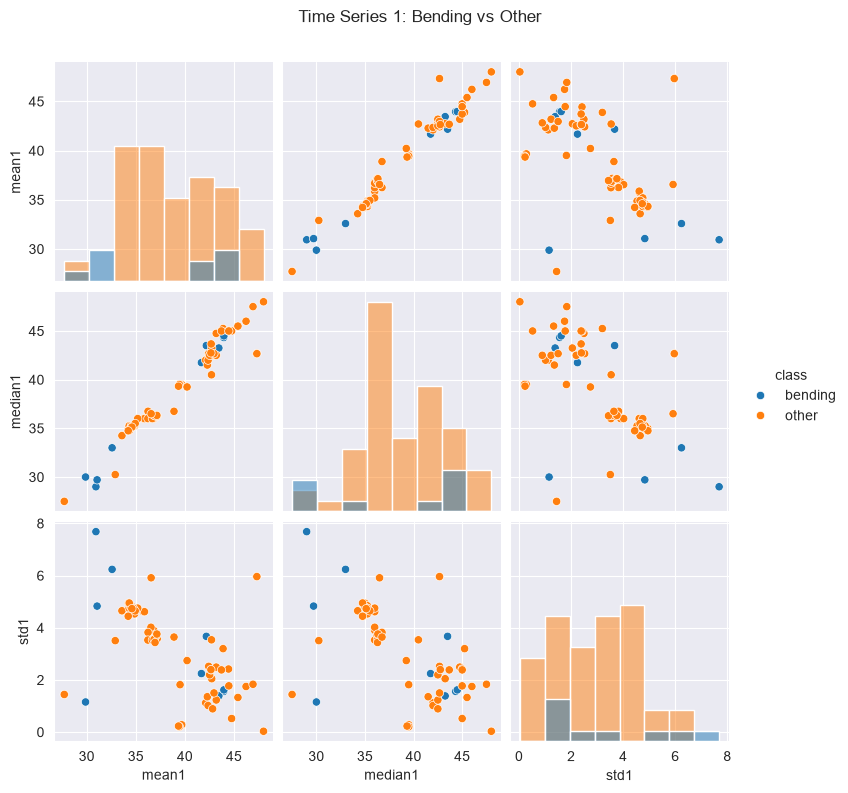

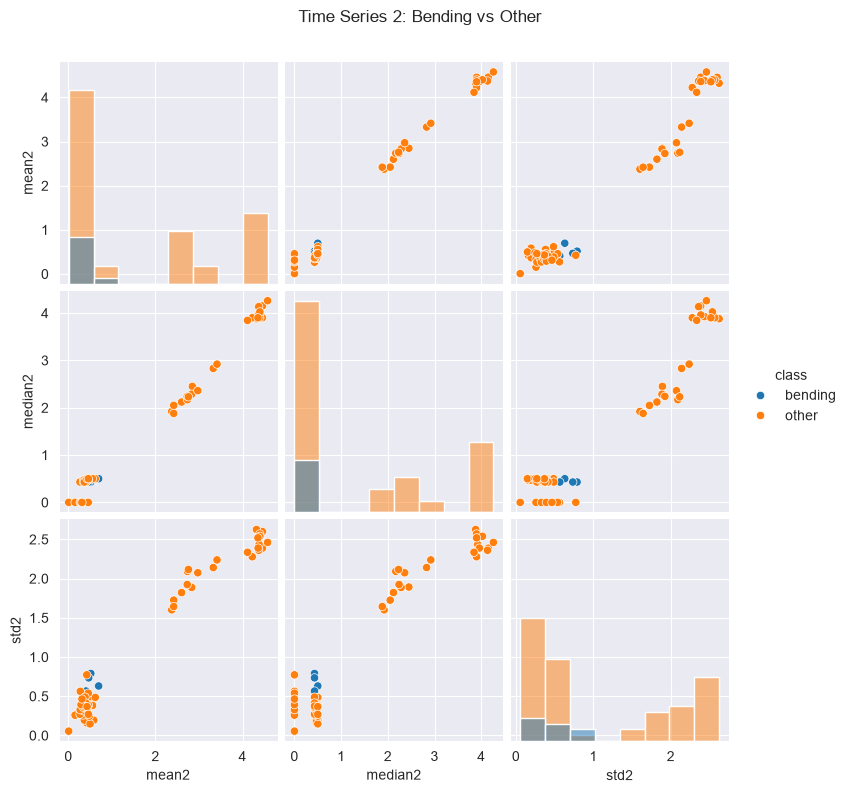

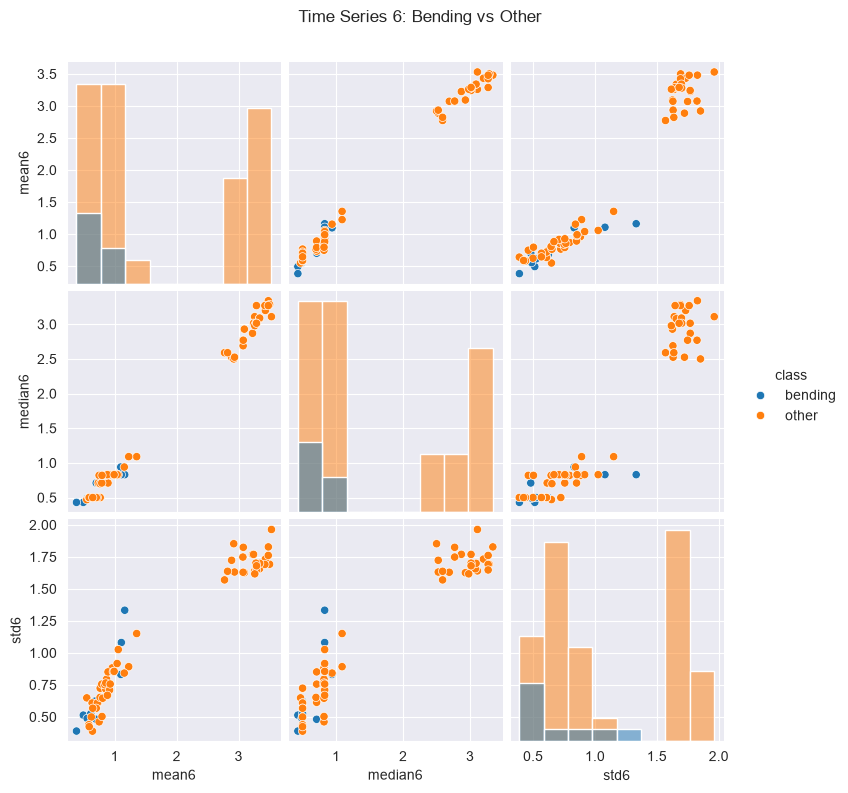

In [4]:
train_path = os.path.join("Train_set")

train_features = []

for activity in activities:
    folder = os.path.join(train_path, activity)
    for file in os.listdir(folder):
        if not file.endswith('.csv'):
            continue
        file_path = os.path.join(folder, file)
        df = pd.read_csv(file_path, header=None,names=["time", 'avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23'], comment='#', sep=r'[,\s]+', engine='python', usecols = range(7))
        instances = {"activity": activity, "file" : file}

        for i , col in enumerate(time_series, start=1):
            instances[f'min{i}'] = df[col].min()
            instances[f'max{i}'] = df[col].max()
            instances[f'mean{i}'] = df[col].mean()
            instances[f'median{i}'] = df[col].median()
            instances[f'std{i}'] = df[col].std()
            instances[f"first_quartile{i}"] = df[col].quantile(0.25)
            instances[f"third_quartile{i}"] = df[col].quantile(0.75)
        train_features.append(instances)
feature_df = pd.DataFrame(train_features)
# feature_df.head()

feature_df["class"] = feature_df["activity"].apply(
    lambda x: "bending" if x in ["bending1", "bending2"] else "other"
)


for i in [1, 2, 6]:
    selected = [f"mean{i}", f"median{i}", f"std{i}"]

    sns.pairplot(feature_df, vars = selected, hue = "class", diag_kind="hist")
    plt.suptitle(f"Time Series {i}: Bending vs Other", y=1.05)
    plt.show()

#### ii. Splitted Plots

In [5]:
split = []
for activity in activities:
    folder = os.path.join(train_path, activity)
    for file in os.listdir(folder):
        if not file.endswith('.csv'):
            continue
        file_path = os.path.join(folder, file)
        df = pd.read_csv(file_path, header=None,names=["time", 'avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23'], comment='#', sep=r'[,\s]+', engine='python', usecols = range(7))
        instances = {"activity": activity, "file" : file}

        mid = len(df) //2
        part1 = df.iloc[:mid]
        part2 = df.iloc[mid:]

        for i in [1,2,6]:
            col = time_series[i-1]
            instances[f"mean{i}_part1"] = part1[col].mean()
            instances[f"mean{i}_part2"] = part2[col].mean()
            instances[f"median{i}_part1"] = part1[col].median()
            instances[f"median{i}_part2"] = part2[col].median()
            instances[f"std{i}_part1"] = part1[col].std()
            instances[f"std{i}_part2"] = part2[col].std()
        split.append(instances)
split_df = pd.DataFrame(split)
split_df.head()


,activity,file,mean1_part1,mean1_part2,median1_part1,median1_part2,std1_part1,std1_part2,mean2_part1,mean2_part2,median2_part1,median2_part2,std2_part1,std2_part2,mean6_part1,mean6_part2,median6_part1,median6_part2,std6_part1,std6_part2
0,bending1,dataset3.csv,44.057167,43.851833,44.50,43.50,1.556971,1.557168,0.381042,0.471458,0.470,0.5,0.329540,0.342346,0.598250,0.388333,0.500,0.00,0.526656,0.478528
1,bending1,dataset4.csv,43.278875,41.080750,45.00,42.00,3.473355,3.537481,0.673292,0.718792,0.485,0.5,0.634285,0.627915,0.640958,0.586083,0.765,0.47,0.554542,0.491873
2,bending1,dataset5.csv,41.621208,41.734917,42.33,41.50,3.118644,0.595920,0.623083,0.448875,0.500,0.5,0.489595,0.273050,0.419083,0.347500,0.430,0.43,0.411200,0.363144
3,bending1,dataset6.csv,44.117042,42.792875,45.00,42.67,1.359836,1.058792,0.250042,0.506125,0.000,0.5,0.314099,0.260761,0.815417,0.543875,0.710,0.50,0.718016,0.473445
4,bending1,dataset7.csv,43.486208,44.452042,43.71,44.50,1.281976,1.771251,0.378667,0.447583,0.470,0.5,0.284434,0.235493,0.524875,0.585750,0.470,0.50,0.486847,0.487918


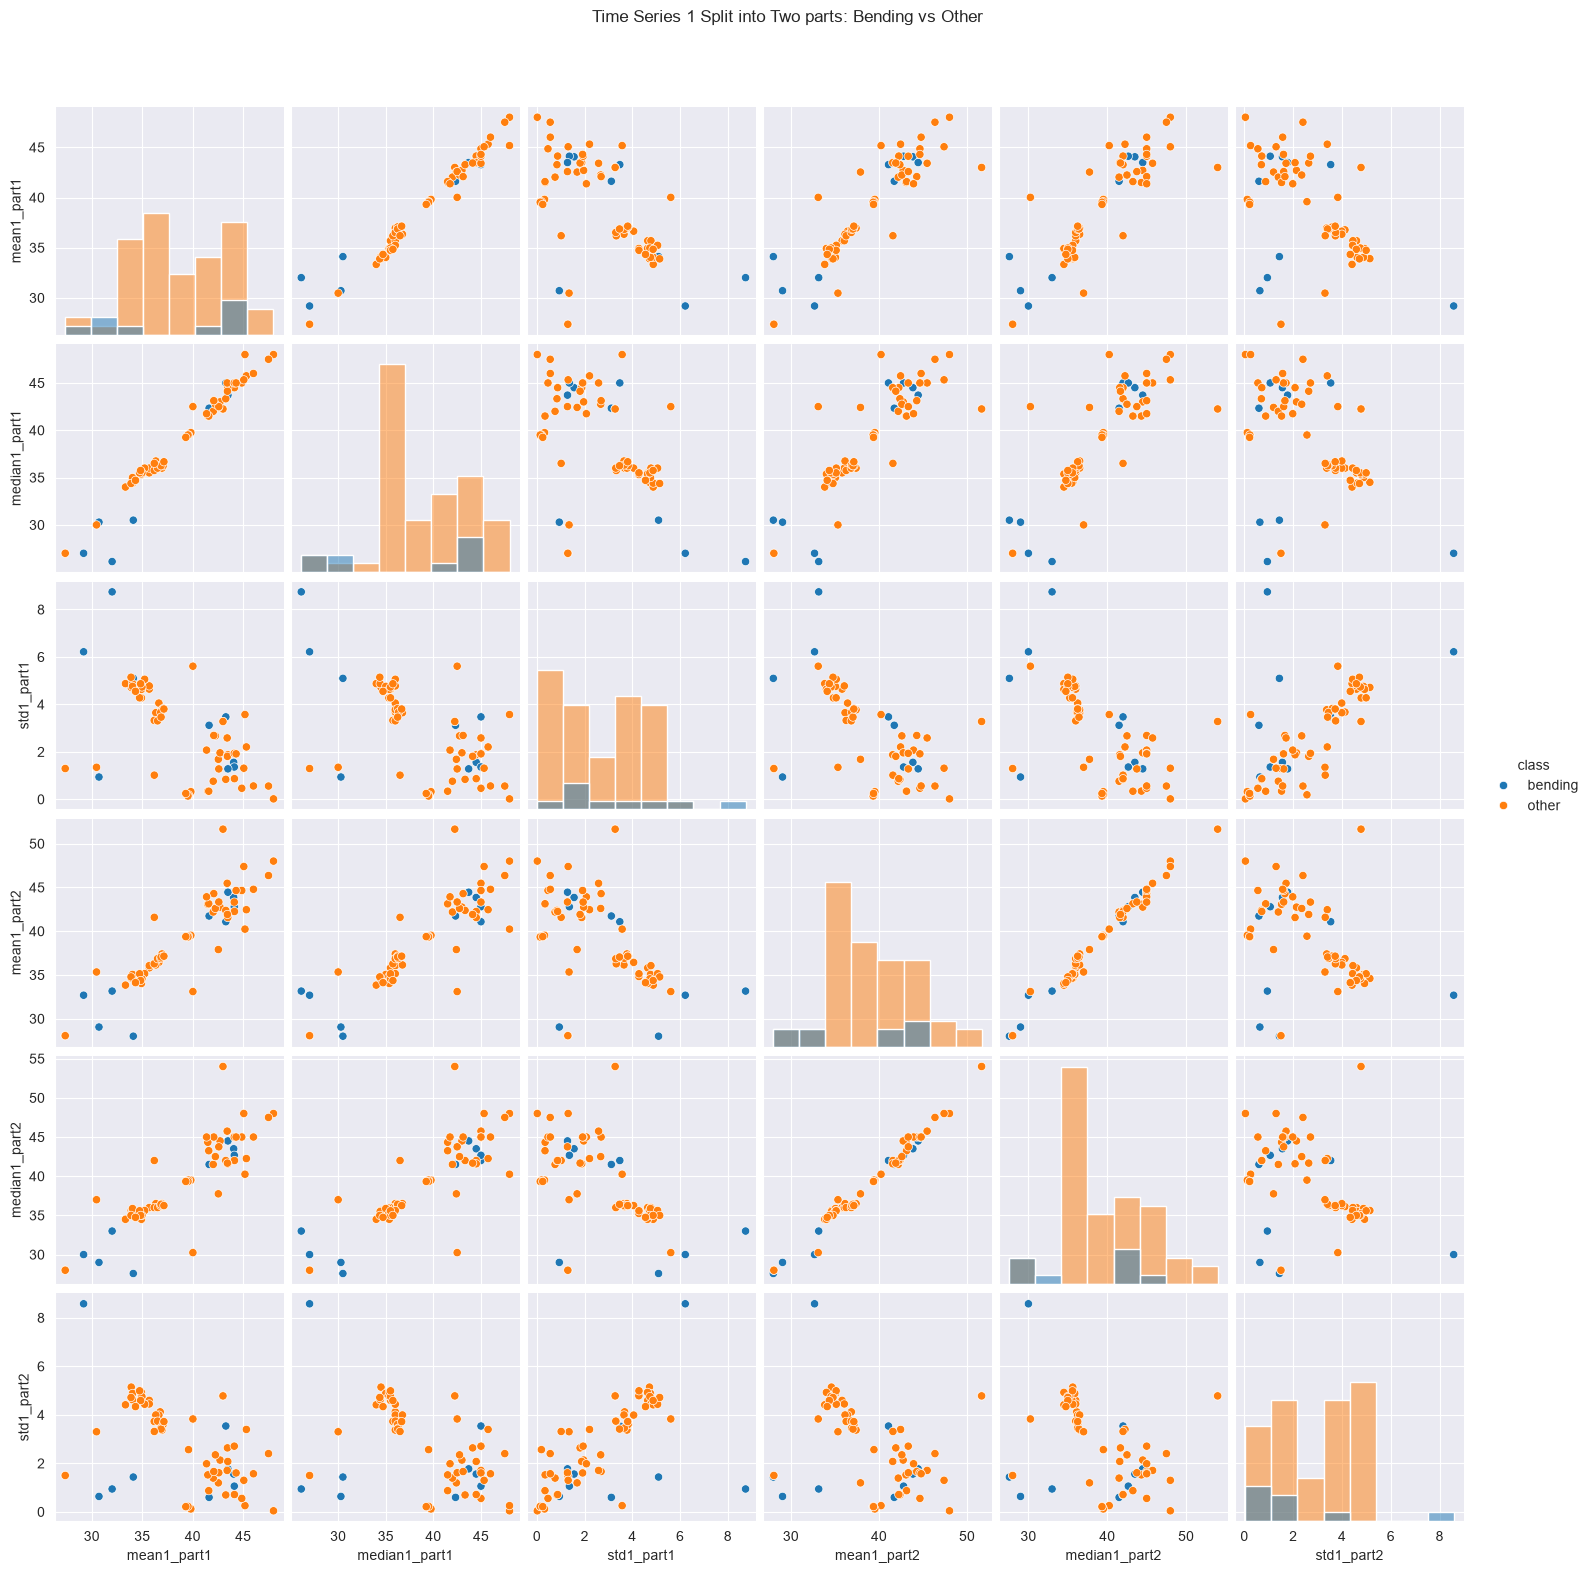

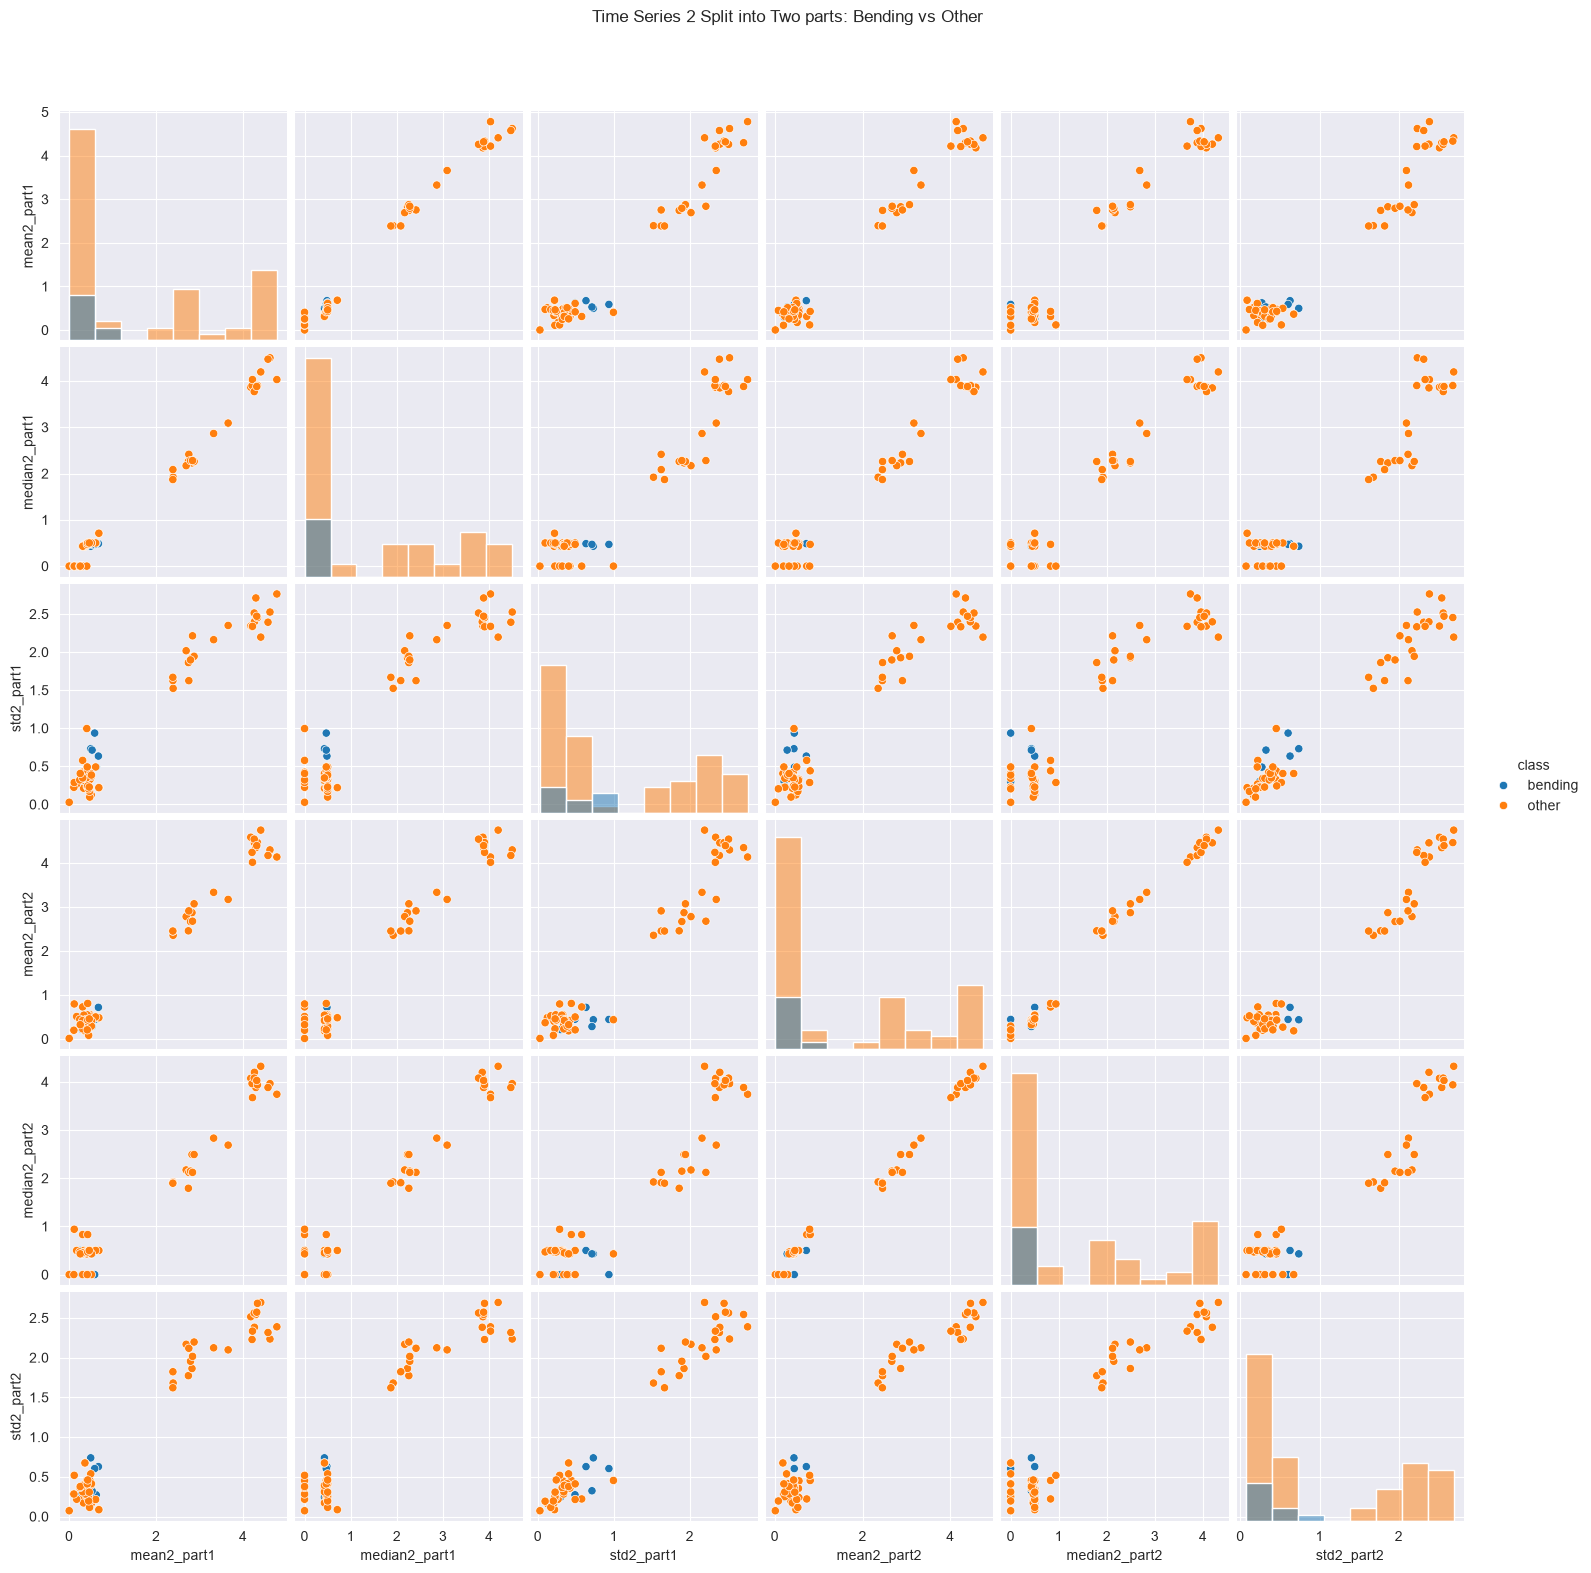

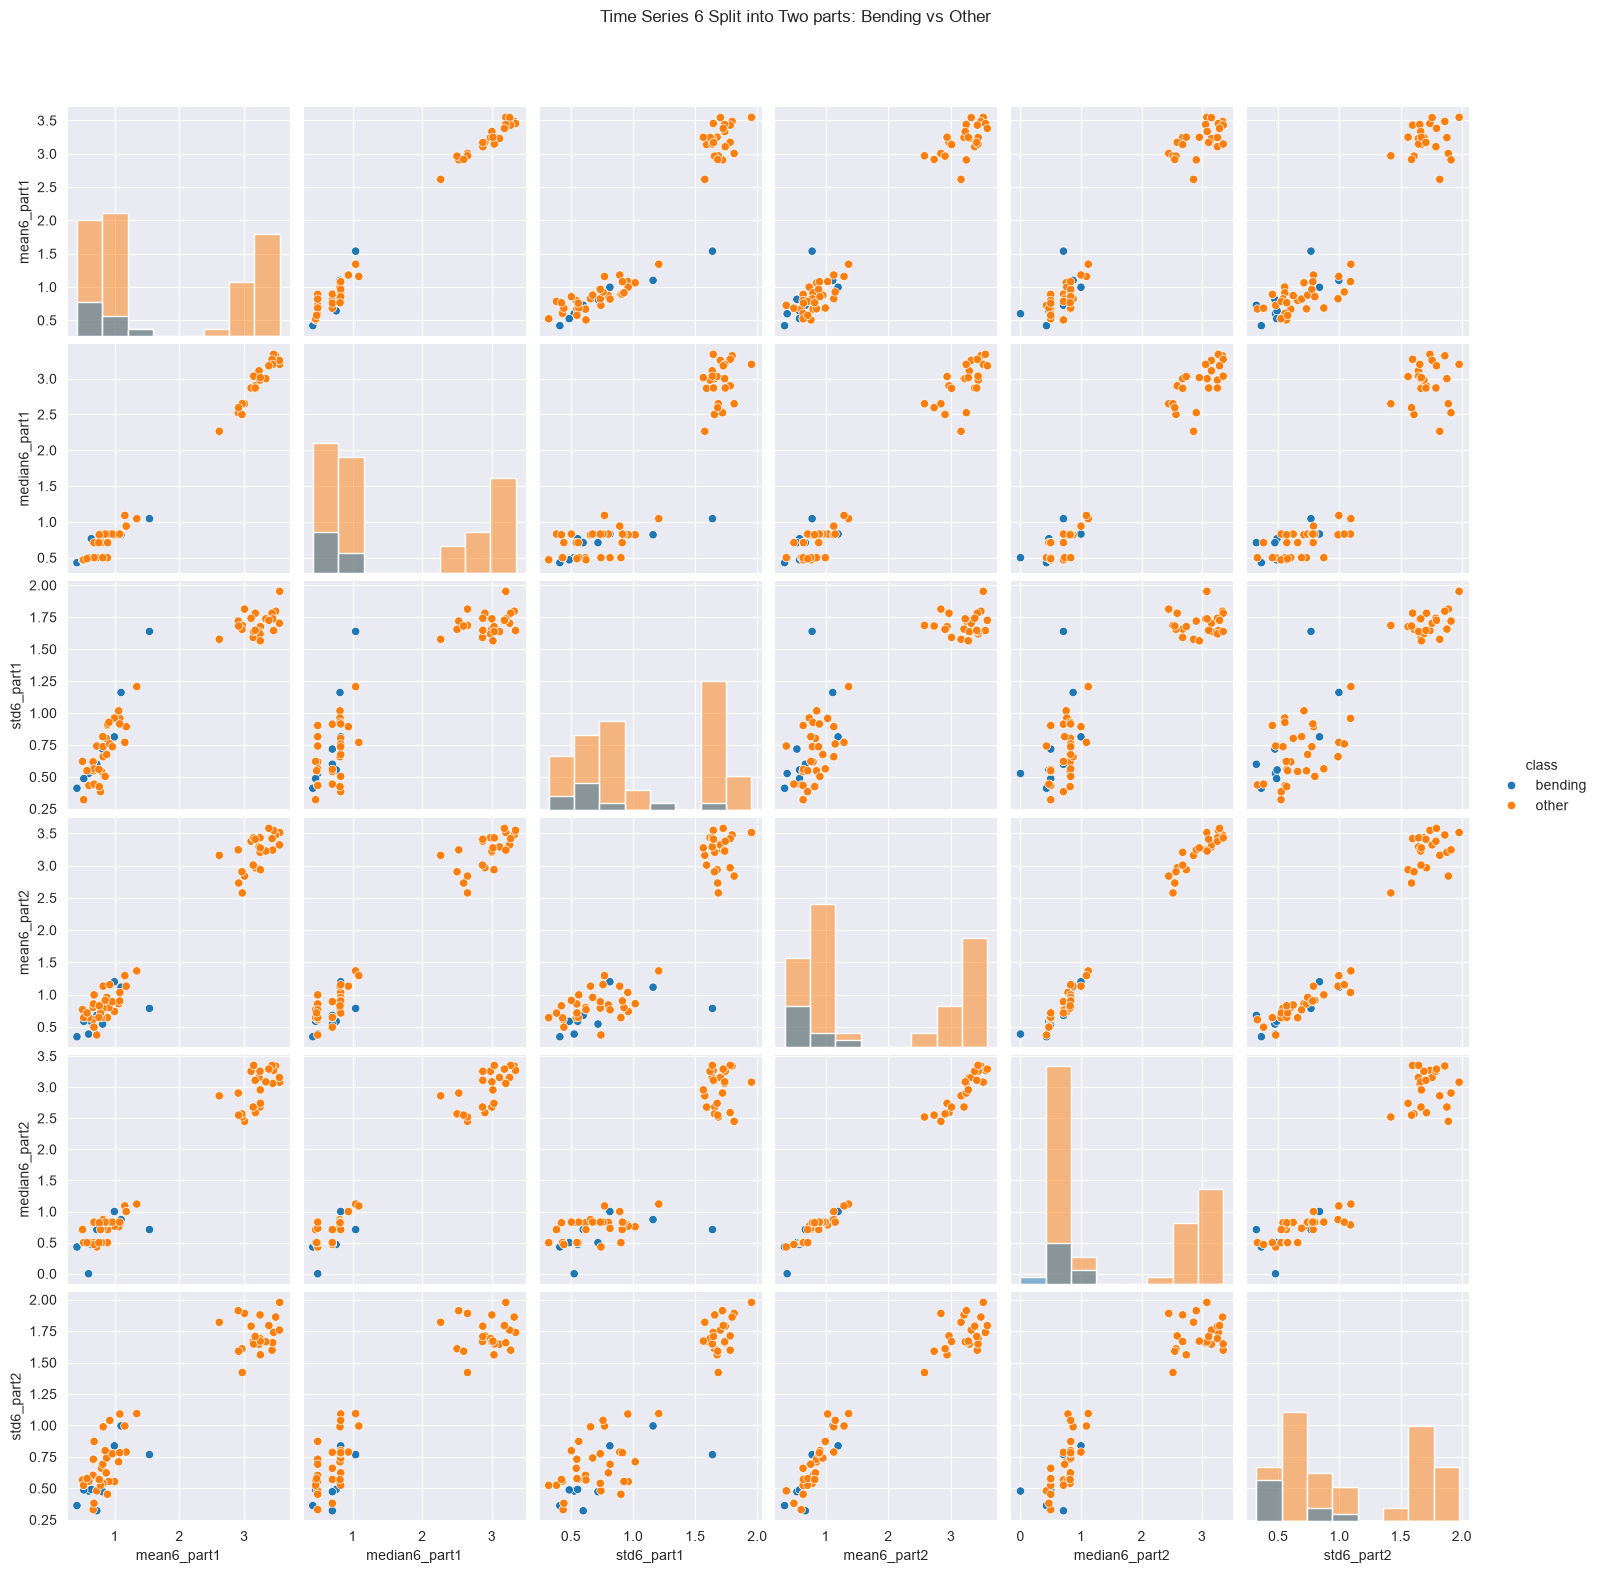

In [6]:
split_df["class"] = split_df["activity"].apply(
    lambda x: "bending" if x in ["bending1", "bending2"] else "other"
)

for i in [1, 2, 6]:
    selected = [f"mean{i}_part1", f"median{i}_part1", f"std{i}_part1",f"mean{i}_part2", f"median{i}_part2",f"std{i}_part2"]

    sns.pairplot(split_df, vars =selected, hue = "class", diag_kind="hist")
    plt.suptitle(f"Time Series {i} Split into Two parts: Bending vs Other", y=1.05)
    plt.show()

After splitting each time series into two equal parts, the overall separation between bending and other activities is similar to what we got in (i). With the split we have additional features which provides us more detailed information about with-in instance variation but there is no considerable visual changes in class separation. In both sections' result, for time series 1 and 6 we get substantial overlaps and scatter between bending and other activities, while time series 2 we can see some relatively clear separation between them.

#### iii. Time Series Segments

In [17]:
def extract_features (l, path):
    extract = []
    for activity in activities:
        folder = os.path.join(path, activity)
        for file in os.listdir(folder):
            if not file.endswith('.csv'):
                continue
            file_path = os.path.join(folder, file)
            df = pd.read_csv(file_path, header=None,names=["time", 'avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23'], comment='#', sep=r'[,\s]+', engine='python', usecols = range(7))
            instances = {"activity": activity, "file" : file}

            split_indices = np.array_split(np.arange(len(df)), l)

            for num, indices in enumerate(split_indices, start=1):
                part = df.iloc[indices]

                for i, col in enumerate(time_series, start=1):
                    instances[f"min{i}_part{num}"] = part[col].min()
                    instances[f"max{i}_part{num}"] = part[col].max()
                    instances[f"mean{i}_part{num}"] = part[col].mean()
                    instances[f"median{i}_part{num}"] = part[col].median()
                    instances[f"std{i}_part{num}"] = part[col].std()
                    instances[f"first_quartile{i}_part{num}"] = part[col].quantile(0.25)
                    instances[f"third_quartile{i}_part{num}"] = part[col].quantile(0.75)
            if activity in ["bending1", "bending2"]:
                instances["class"] = 1
            else:
                instances["class"] = 0
            extract.append(instances)
    return pd.DataFrame(extract)



In [18]:
from sklearn .feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn import datasets
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []
p_list = list(range(1,20))

for l in range(1,21):
    # print(f"l = {l}")

    df = extract_features(l, train_path)
    X = df.drop(columns=["activity", "file", "class"])
    y = df["class"]
    n_features = X.shape[1]

    for p in p_list:
        if p > n_features:
            continue
        scores =[]

        for train_index, val_index in cv.split(X,y):
            X_train, X_val = X.iloc[train_index], X.iloc[val_index]
            y_train, y_val = y.iloc[train_index], y.iloc[val_index]
            scaler = StandardScaler()

            X_train_scaled = scaler.fit_transform(X_train)
            X_val_scaled = scaler.transform(X_val)

            model = LogisticRegression(C = 1e6, max_iter = 2000, solver = "liblinear")

            rfe = RFE(estimator=model, n_features_to_select = p,step=0.1)

            X_train_rfe = rfe.fit_transform(X_train_scaled, y_train)
            X_val_rfe = rfe.transform(X_val_scaled)

            final_log = LogisticRegression(C = 1e6, max_iter = 2000, solver = "liblinear")
            final_log.fit(X_train_rfe, y_train)

            y_pred = final_log.predict(X_val_rfe)
            scores.append(accuracy_score(y_val, y_pred))

        results.append({"l":l, "p":p, "mean_cv_accuracy":np.mean(scores)})

result_df = pd.DataFrame(results)
result_df = result_df.sort_values(by =["mean_cv_accuracy", "p","l"], ascending=[False, True, True])
result_df.head(10)

,l,p,mean_cv_accuracy
210,12,2,0.985714
2,1,3,0.985714
12,1,13,0.985714
18,1,19,0.985714
43,3,6,0.971429
195,11,6,0.971429
44,3,7,0.971429
196,11,7,0.971429
45,3,8,0.971429
46,3,9,0.971429


In [31]:
best_l =12
best_p = 2
best_cv_accuracy = 0.985714
best_df = extract_features(best_l, train_path)
X = best_df.drop(columns=["activity", "file", "class"])
y = best_df["class"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
model = LogisticRegression(C = 1e6, max_iter = 2000, solver = "liblinear")
rfe = RFE(estimator=model, n_features_to_select = best_p, step=0.1)
X_rfe = rfe.fit_transform(X_scaled, y)
selected_features = X.columns[rfe.support_]
print("Selected features:", selected_features)
final_log = LogisticRegression(C = 1e6, max_iter = 2000, solver = "liblinear")
final_log.fit(X_rfe, y)
print("Intercept:", final_log.intercept_)
print("Coefficients:", final_log.coef_)


Selected features: Index(['first_quartile5_part2', 'first_quartile1_part3'], dtype='str')
Intercept: [-10.26765943]
Coefficients: [[10.93020423 -2.25038545]]


Stratified 5-fold CV was used to select l and p, and the best CV accuracy is approximately 0.9857 produced by several pairs of (l,p). I selected (l,p) = (12,2) here because it uses the least amount of features. The correct way to perform CV is to do feature extraction separately within each training fold of cv. For each fold, scaler and RFE are fitted using the training portion only and then apply the resulting transformation to the validation part. I think the wrong way to do this is to perform RFE once using the entire training data and then perform cv on the previous already-selected feature. The problem here is that the validation observations would have influence on feature-selection, causing data leakage.

#### iv. Confusion Matrix

[[59  1]
 [ 0  9]]


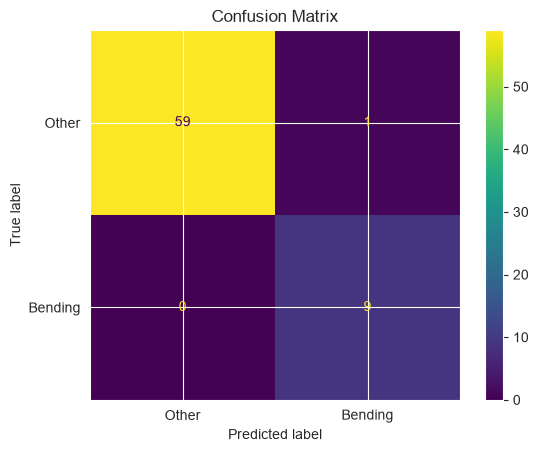

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_auc_score, roc_curve

y_pred = final_log.predict(X_rfe)
cm = confusion_matrix(y, y_pred)
print(cm)

dis = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Other", "Bending"])
dis.plot()
plt.title("Confusion Matrix")
plt.show()

AUC: 0.9962962962962962


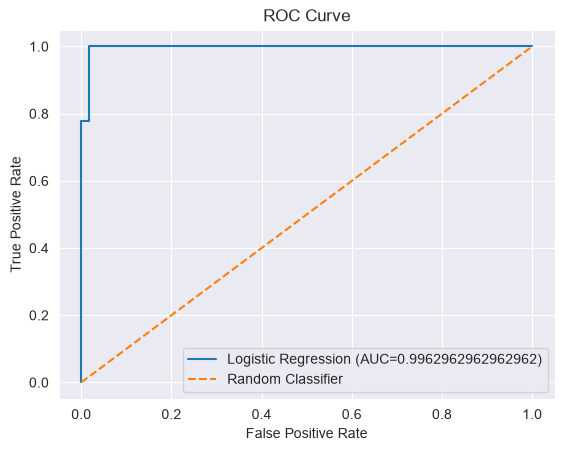

In [21]:
y_prob = final_log.predict_proba(X_rfe)[:,1]

fpr, tpr, threshold = roc_curve(y, y_prob)
auc = roc_auc_score(y, y_prob)
print("AUC:", auc)

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC={auc})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [22]:
print("Intercept:", final_log.intercept_)
print("Coefficients:", final_log.coef_)

Intercept: [-10.26765943]
Coefficients: [[10.93020423 -2.25038545]]


In [23]:
X_selected = pd.DataFrame(X_rfe, columns = selected_features, index = X.index)
X_selected_sm = sm.add_constant(X_selected)
logit_model = sm.Logit(y, X_selected_sm)
logit_result = logit_model.fit()
result_table = pd.DataFrame({
    "Coefficients": logit_result.params,
    "Std_Error": logit_result.bse,
    "z_value": logit_result.tvalues,
    "p_value": logit_result.pvalues,
})

result_table



Optimization terminated successfully.
         Current function value: 0.041227
         Iterations 13


,Coefficients,Std_Error,z_value,p_value
const,-10.269041,7.368069,-1.393722,0.163401
first_quartile5_part2,10.931556,7.260476,1.505625,0.132163
first_quartile1_part3,-2.250728,2.105222,-1.069117,0.285017


Here we have the parameters and p-values

#### v. Test Classifier

In [32]:
test_path = os.path.join("Test_set")
test_df = extract_features(best_l, test_path)

X_test = test_df.drop(columns=["activity", "file", "class"])
y_test = test_df["class"]

X_test_scaled = scaler.transform(X_test)
X_test_rfe = rfe.transform(X_test_scaled)
y_test_pred = final_log.predict(X_test_rfe)

test_accuracy = accuracy_score(y_test, y_test_pred)
print("Test Accuracy:", test_accuracy)
print("Best CV Accuracy:", best_cv_accuracy)

Test Accuracy: 0.9473684210526315
Best CV Accuracy: 0.985714


Here we apply the log regression classifier on the test data and achieved the accuracy 0.947368, compared to previous 5-fold cv accuracy 0.985714. The test result is slight lower but still close to the cv result.

#### vi. Separation

I would say the two classes seems to be nearly well-seperated, since the training AUC is 0.9963 and the coefficients of our logistic regression is relatively large, suggesting that a small number of features strongly separate bending from other activities. This well-separation can make our estimation on log regression coefficient unstable and lead to large standard errors, which are shown in sm table results in iv

#### vii. Imbalance

In [48]:
case_control_df = pd.DataFrame(X_rfe, columns = selected_features)
case_control_df["class"] = y.values
case = case_control_df[case_control_df["class"] == 1]
control = case_control_df[case_control_df["class"] == 0]

control_sample = control.sample(n=len(case), random_state=42)

case_control_result = pd.concat([case, control_sample], ignore_index=True)

X_case_control = case_control_result[selected_features]
y_case_control = case_control_result["class"]
case_control_model = LogisticRegression(C = 1e6, max_iter = 2000, solver = "liblinear")
case_control_model.fit(X_case_control, y_case_control)


beta0_case_control = case_control_model.intercept_[0]
beta0_adjusted = (beta0_case_control + np.log(9/60))

beta = case_control_model.coef_[0]
log_odds = (beta0_adjusted + X_rfe @ beta )
case_control_prob = 1/ (1+np.exp(-log_odds))
case_control_pred = (case_control_prob >= 0.5).astype(int)

print("Intercept before adjustment:", beta0_case_control)
print("Intercept after adjustment:", beta0_adjusted)

Intercept before adjustment: -22.632530642653222
Intercept after adjustment: -24.529650627539105


[[59  1]
 [ 0  9]]


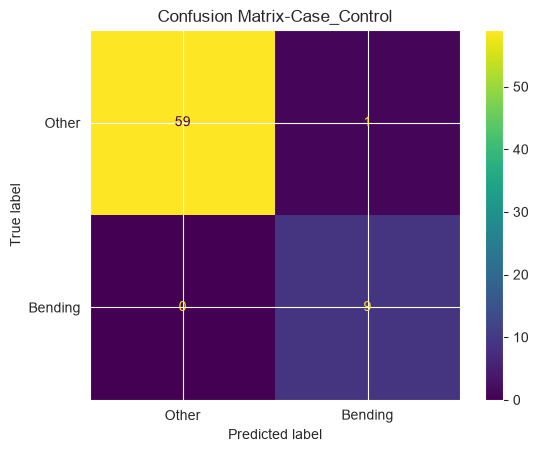

In [46]:
cc_cm = confusion_matrix(y, case_control_pred)
print(cc_cm)

dis = ConfusionMatrixDisplay(cc_cm, display_labels=["Other", "Bending"])
dis.plot()
plt.title("Confusion Matrix-Case_Control")
plt.show()

Case-Control AUC: 0.9944444444444444


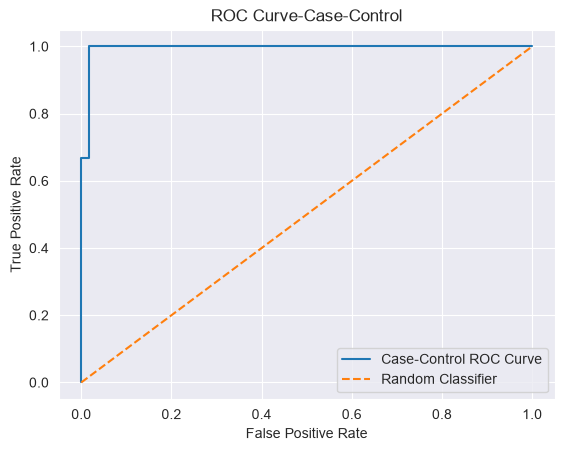

In [47]:
cc_fpr, cc_tpr, cc_threshold = roc_curve(y, case_control_prob)
cc_auc = roc_auc_score(y, case_control_prob)
print("Case-Control AUC:", cc_auc)

plt.plot(cc_fpr, cc_tpr, label="Case-Control ROC Curve")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve-Case-Control")
plt.legend()
plt.show()

Here are the results from adjusted model. Our previous model was indeed imbalanced, with 9 bending instance and 60 non-bending instances. Thus i perform this case-control sampling by keeping all of the bending instances and randomly selected 9 non-bending instances. Then the log regression was fitted and intercept was adjusted

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [56]:
C_list = np.logspace(-4,4,17)
l1_result = []

for l in range(1,21):
    df = extract_features(l, train_path)

    X = df.drop(columns=["activity", "file", "class"])
    y = df["class"]
    for c in C_list:
        scores=[]
        num_selected = []

        for train_index, val_index in cv.split(X, y):
            X_train, X_val = X.iloc[train_index], X.iloc[val_index]
            y_train, y_val = y.iloc[train_index], y.iloc[val_index]

            scaler = StandardScaler()
            X_train_scaled = scaler.fit_transform(X_train)
            X_val_scaled = scaler.transform(X_val)

            model = LogisticRegression(C = c, max_iter = 2000, solver = "liblinear", l1_ratio = 1)
            model.fit(X_train_scaled, y_train)
            y_pred = model.predict(X_val_scaled)
            scores.append(accuracy_score(y_val, y_pred))
            selected = np.sum(model.coef_[0] !=0)
            num_selected.append(selected)
        l1_result.append({"l":l, "C": c,"mean_cv_accuracy":np.mean(scores), "std_cv_accuracy":np.std(scores), "mean_num_features":np.mean(num_selected)})

l1_result_df = pd.DataFrame(l1_result)
l1_result_df = l1_result_df.sort_values(by=["mean_cv_accuracy", "mean_num_features", "l"], ascending=[False, True, True])
l1_result_df.head(10)

,l,C,mean_cv_accuracy,std_cv_accuracy,mean_num_features
15,1,3162.277660,0.985714,0.028571,22.2
16,1,10000.000000,0.985714,0.028571,35.6
9,1,3.162278,0.971429,0.034993,7.4
195,12,1.000000,0.971429,0.034993,7.8
27,2,10.000000,0.971429,0.034993,9.6
196,12,3.162278,0.971429,0.034993,9.8
197,12,10.000000,0.971429,0.034993,12.2
332,20,3.162278,0.971429,0.034993,13.0
14,1,1000.000000,0.971429,0.034993,17.8
198,12,31.622777,0.971429,0.034993,18.4


In [57]:
best_l1 =1
best_C = 3162.27766

best_l1_df =extract_features(best_l1, train_path)
X_l1 = best_l1_df.drop(columns=["activity", "file", "class"])
y_l1 = best_l1_df["class"]
l1_scaler = StandardScaler()
X_l1_scaled = l1_scaler.fit_transform(X_l1)

final_l1 = LogisticRegression(C = best_C, max_iter = 2000, solver = "liblinear", l1_ratio = 1,random_state=42)
final_l1.fit(X_l1_scaled, y_l1)

selected_l1_features = X_l1.columns[final_l1.coef_[0] != 0]
# print("Selected features:", selected_l1_features)

l1_coef_df =pd.DataFrame({"feature": X_l1.columns, "coefficient": final_l1.coef_[0]})
l1_coef_df = l1_coef_df[l1_coef_df["coefficient"] != 0]
l1_coef_df

,feature,coefficient
0,min1_part1,-2.548678
1,max1_part1,1.061282
2,mean1_part1,-0.384197
3,median1_part1,-0.238516
4,std1_part1,0.211420
6,third_quartile1_part1,-3.063717
8,max2_part1,-2.465222
11,std2_part1,-0.179258
14,min3_part1,-0.569905
15,max3_part1,0.444416


Here again 5-fold cv was used to select l and C. The best cv accuracy was 0.985714. I select best L1=1 and best C =3162.2776. After fit the final model on training observations, 25 of 42 features has non zero coefficient while the remaining ones are reduced by L1 regulation

#### ii. Comparison

From 2a we get best l at 12 and only 2 selected features; here we are at l=1 and 25 non-zero features and in both cases we have roughly the same cv accuracy. But since our RFE approach only have two features, it is easier to interpret. On the other hand, L1-penalized model is easier to implement because feature selection is automatically performed by the regulation term during model fitting. By contrast, RFE one needs us to do separate feature-selection process.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [60]:
cv_multinomial = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)

multi_result = []
for l in range(1,21):
    df = extract_features(l, train_path)
    X = df.drop(columns=["activity", "file", "class"])
    y = df["activity"]
    for c in C_list:
        scores=[]
        num_selected = []
        for train_index, val_index in cv_multinomial.split(X, y):
            X_train, X_val = X.iloc[train_index], X.iloc[val_index]
            y_train, y_val = y.iloc[train_index], y.iloc[val_index]
            scaler = StandardScaler()
            X_train_scaled = scaler.fit_transform(X_train)
            X_val_scaled = scaler.transform(X_val)

            model = LogisticRegression(C = c, max_iter = 10000, solver = "saga", l1_ratio = 1)
            model.fit(X_train_scaled, y_train)
            y_pred = model.predict(X_val_scaled)
            scores.append(accuracy_score(y_val, y_pred))

            selected = np.any(model.coef_ !=0, axis=0)
            num_selected.append(np.sum(selected))

        multi_result.append({
            "l":l,
            "C": c,
            "mean_cv_accuracy":np.mean(scores),
            "std_cv_accuracy":np.std(scores),
            "mean_num_features":np.mean(num_selected),
        })

multi_result_df = pd.DataFrame(multi_result)
multi_result_df = multi_result_df.sort_values(by=["mean_cv_accuracy","mean_num_features", "l"], ascending=[False, True, True])
multi_result_df.head(10)

C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\XYZ\miniconda3\Lib\site-pa

,l,C,mean_cv_accuracy,std_cv_accuracy,mean_num_features
26,2,3.162278,0.914286,0.053452,38.6
27,2,10.000000,0.914286,0.053452,52.4
29,2,100.000000,0.914286,0.053452,82.8
30,2,316.227766,0.914286,0.053452,82.8
9,1,3.162278,0.913187,0.053203,21.0
25,2,1.000000,0.900000,0.072843,28.8
28,2,31.622777,0.900000,0.057143,73.6
31,2,1000.000000,0.900000,0.057143,82.8
32,2,3162.277660,0.900000,0.057143,82.8
33,2,10000.000000,0.900000,0.057143,82.8


Here we get the best cv accuracy at 0.9143, and I select l=2 and C=3.162278 since they contain the fewest features

In [62]:
best_multi_l1 = 2
best_multi_c = 3.162278
best_multi_df = extract_features(best_multi_l1, train_path)
X_multi = best_multi_df.drop(columns=["activity", "file", "class"])
y_multi = best_multi_df["activity"]

mullti_scaler = StandardScaler()
X_multi_scaled = mullti_scaler.fit_transform(X_multi)

final_multi = LogisticRegression(
    C = best_multi_c,
    max_iter = 10000,
    solver = "saga",
    l1_ratio = 1,
    random_state=42,
)
final_multi.fit(X_multi_scaled, y_multi)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",3.162278
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",1
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mu

In [63]:
selected_multi_features = X_multi.columns[np.any(final_multi.coef_ != 0, axis=0)]
print(selected_multi_features)

Index(['max1_part1', 'median1_part1', 'std1_part1', 'third_quartile1_part1',
       'median2_part1', 'first_quartile2_part1', 'median3_part1', 'std3_part1',
       'first_quartile3_part1', 'third_quartile3_part1', 'min4_part1',
       'max4_part1', 'std4_part1', 'min5_part1', 'max5_part1', 'mean5_part1',
       'median5_part1', 'std5_part1', 'third_quartile5_part1', 'min6_part1',
       'std6_part1', 'max1_part2', 'min2_part2', 'median2_part2',
       'first_quartile2_part2', 'max3_part2', 'median3_part2', 'std3_part2',
       'third_quartile3_part2', 'std4_part2', 'third_quartile4_part2',
       'min5_part2', 'std5_part2', 'first_quartile5_part2', 'min6_part2',
       'max6_part2', 'std6_part2'],
      dtype='str')


In [64]:
multi_test_df = extract_features(best_multi_l1, test_path)
X_multi_test = multi_test_df.drop(columns=["activity", "file", "class"])
y_multi_test = multi_test_df["activity"]
X_multi_test_scaled = mullti_scaler.transform(X_multi_test)
y_multi_pred = final_multi.predict(X_multi_test_scaled)

multi_test_score = accuracy_score(y_multi_test, y_multi_pred)
print("Test Error:", 1-multi_test_score)

Test Error: 0.1578947368421053


[[2 0 0 0 0 0 0]
 [0 1 0 0 1 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [1 0 0 0 1 1 0]
 [0 0 0 0 0 3 0]
 [0 0 0 0 0 0 3]]


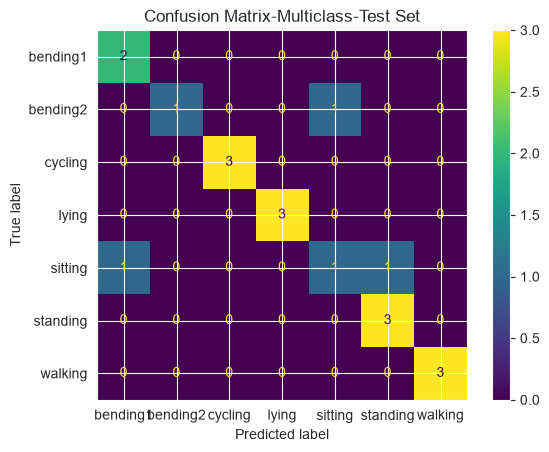

In [65]:
multi_cm = confusion_matrix(y_multi_test, y_multi_pred, labels=final_multi.classes_)
print(multi_cm)
dis = ConfusionMatrixDisplay(multi_cm, display_labels=final_multi.classes_)
dis.plot()
plt.title("Confusion Matrix-Multiclass-Test Set")
plt.show()

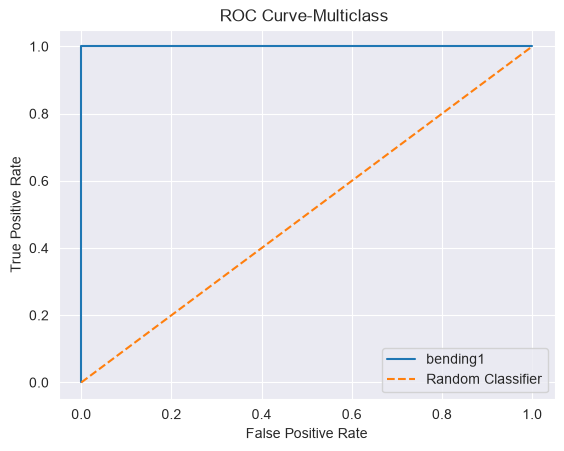

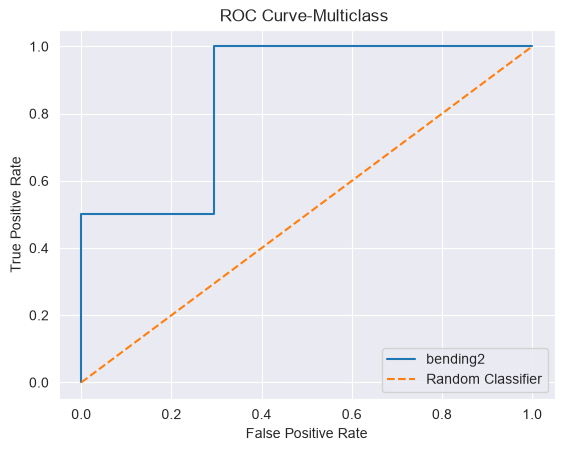

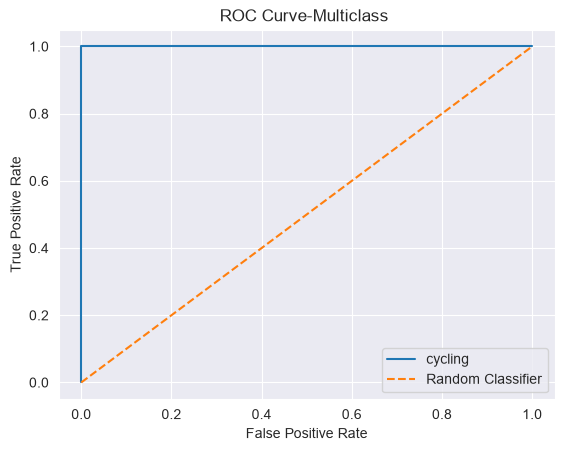

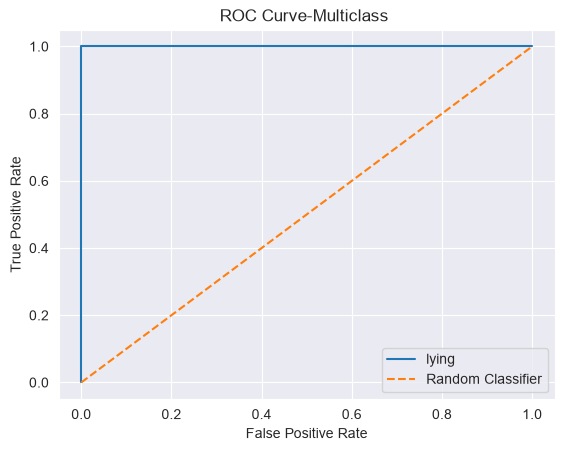

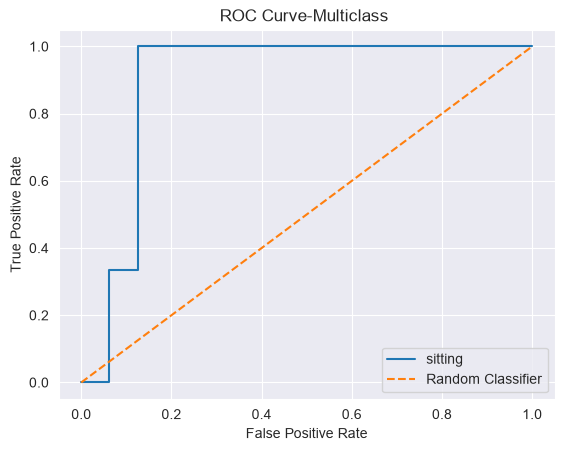

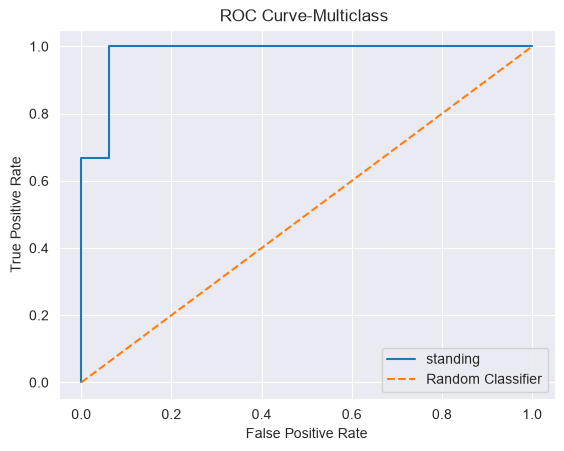

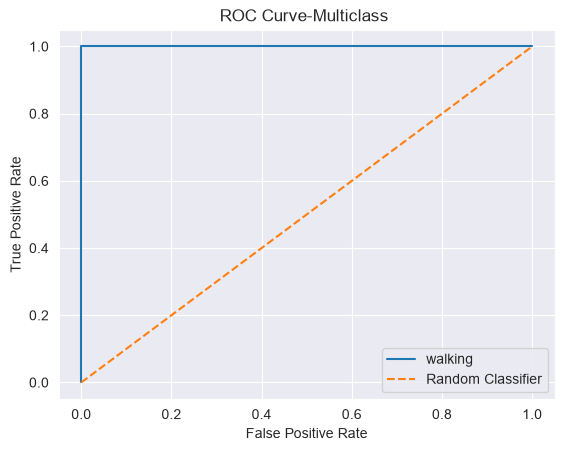

Macro-average AUC: 0.9611344537815126


In [69]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc
y_multi_prob = final_multi.predict_proba(X_multi_test_scaled)
classes = final_multi.classes_
y_multi_bin =label_binarize(y_multi_test, classes=classes)


for i, activity in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_multi_bin[:, i], y_multi_prob[:, i])
    single_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=activity)
    plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve-Multiclass ")
    plt.legend()
    plt.show()

overall_auc = roc_auc_score(y_multi_test, y_multi_prob, labels = classes, multi_class = "ovr", average = "macro")

print("Macro-average AUC:", overall_auc)

For Multiclass Classification problem with K classes, the confusion matrix is a KxK matrix, and each row represents the true class and each column represents the predicted class. Naturally the diagonal entries are correctly classified observations while any other off-diagonal one is misclassified and you can tell where the confusion choice is made.
For ROC curves in multi-class situation, they are extended with one-vs-rest approach. For each class, that class is treated as the positive one against all the rest classes. And then ROC curve is constructed using the predicted probability for that class by plotting the TP rate against FP rate over different classification thresholds. Then in this problem the overall multiclass performance is summarized using macro-average AUC resulting 0.9611, meaning our classifier has strong ability on distinguish each activity.

#### ii. Naive Bayes

In [71]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
cv_nb = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)
nb_results = []
for l in range(1,21):
    print("L =", l)
    df = extract_features(l, train_path)
    X = df.drop(columns=["activity", "file", "class"])
    y = df["activity"]

    gaussian_scores =[]
    multinomial_scores =[]

    for train_index, test_index in cv_nb.split(X, y):
        X_train, X_val = X.iloc[train_index], X.iloc[test_index]
        y_train, y_val = y.iloc[train_index], y.iloc[test_index]

        gaussian_model = GaussianNB()
        gaussian_model.fit(X_train, y_train)
        gaussian_pred = gaussian_model.predict(X_val)
        gaussian_scores.append(accuracy_score(y_val, gaussian_pred))

        multinomial_model = MultinomialNB()
        multinomial_model.fit(X_train, y_train)
        multinomial_pred = multinomial_model.predict(X_val)
        multinomial_scores.append(accuracy_score(y_val, multinomial_pred))
    nb_results.append({"l": l, "gaussian_cv_accuracy": np.mean(gaussian_scores), "multinomial_cv_accuracy": np.mean(multinomial_scores)})

nb_result_df = pd.DataFrame(nb_results)
nb_result_df

L = 1


C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


L = 2


C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


L = 3


C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


L = 4


C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


L = 5


C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


L = 6


C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


L = 7


C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


L = 8


C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


L = 9


C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


L = 10


C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


L = 11


C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


L = 12


C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


L = 13


C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


L = 14


C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


L = 15


C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


L = 16


C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


L = 17


C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


L = 18


C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


L = 19


C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


L = 20


C:\Users\XYZ\miniconda3\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


,l,gaussian_cv_accuracy,multinomial_cv_accuracy
0,1,0.857143,0.854945
1,2,0.827473,0.795604
2,3,0.681319,0.796703
3,4,0.725275,0.782418
4,5,0.652747,0.812088
5,6,0.652747,0.783516
6,7,0.695604,0.783516
7,8,0.667033,0.782418
8,9,0.638462,0.783516
9,10,0.681319,0.797802


In [75]:
best_gaussian = nb_result_df.loc[nb_result_df["gaussian_cv_accuracy"].idxmax() ]
print("Best Gaussian l:", best_gaussian["l"])
print("Best Gaussian CV Accuracy:", best_gaussian["gaussian_cv_accuracy"])
best_multinomial = nb_result_df.loc[nb_result_df["multinomial_cv_accuracy"].idxmax() ]
print("Best Multinomial l:", best_multinomial["l"])
print("Best Multinomial CV Accuracy:", best_multinomial["multinomial_cv_accuracy"])

Best Gaussian l: 1.0
Best Gaussian CV Accuracy: 0.8571428571428573
Best Multinomial l: 1.0
Best Multinomial CV Accuracy: 0.8549450549450549


In [76]:
gaussian_train_df = extract_features(best_gaussian["l"], train_path)
X_gaussian_train = gaussian_train_df.drop(columns=["activity", "file", "class"])
y_gaussian_train = gaussian_train_df["activity"]
final_gaussian = GaussianNB()
final_gaussian.fit(X_gaussian_train, y_gaussian_train)

gaussian_test_df = extract_features(best_gaussian["l"], test_path)
X_gaussian_test = gaussian_test_df.drop(columns=["activity", "file", "class"])
y_gaussian_test = gaussian_test_df["activity"]
gaussian_test_pred = final_gaussian.predict(X_gaussian_test)
gaussian_test_score = accuracy_score(y_gaussian_test, gaussian_test_pred)
print("Gaussian Test Error:", 1-gaussian_test_score)

multinomial_train_df = extract_features(best_multinomial["l"], train_path)
X_multinomial_train = multinomial_train_df.drop(columns=["activity", "file", "class"])
y_multinomial_train = multinomial_train_df["activity"]
final_multinomial = MultinomialNB()
final_multinomial.fit(X_multinomial_train, y_multinomial_train)

multinomial_test_df = extract_features(best_multinomial["l"], test_path)
X_multinomial_test = multinomial_test_df.drop(columns=["activity", "file", "class"])
y_multinomial_test = multinomial_test_df["activity"]
multinomial_test_pred = final_multinomial.predict(X_multinomial_test)
multinomial_test_score = accuracy_score(y_multinomial_test, multinomial_test_pred)
print("Multinomial Test Error:", 1-multinomial_test_score)


Gaussian Test Error: 0.10526315789473684
Multinomial Test Error: 0.10526315789473684


[[2 0 0 0 0 0 0]
 [0 2 0 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 2 1 0 0]
 [0 0 0 0 3 0 0]
 [0 0 0 0 1 2 0]
 [0 0 0 0 0 0 3]]


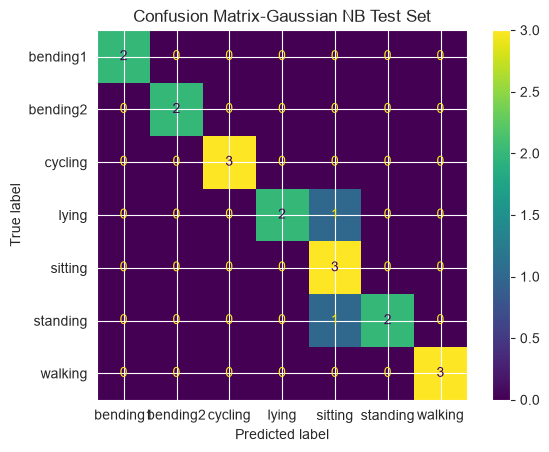

In [78]:
gaussian_cm = confusion_matrix(y_gaussian_test, gaussian_test_pred, labels=final_gaussian.classes_)
print(gaussian_cm)
disp = ConfusionMatrixDisplay(gaussian_cm, display_labels=final_gaussian.classes_)
disp.plot()
plt.title("Confusion Matrix-Gaussian NB Test Set")
plt.show()

[[2 0 0 0 0 0 0]
 [0 2 0 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [0 0 0 0 2 1 0]
 [0 0 0 1 0 2 0]
 [0 0 0 0 0 0 3]]


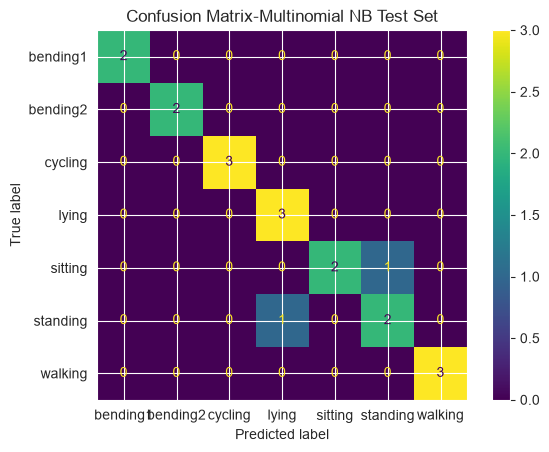

In [79]:
multinomial_cm = confusion_matrix(y_multinomial_test, multinomial_test_pred, labels=final_multinomial.classes_)
print(multinomial_cm)
dis = ConfusionMatrixDisplay(multinomial_cm, display_labels=final_multinomial.classes_)
dis.plot()
plt.title("Confusion Matrix-Multinomial NB Test Set")
plt.show()

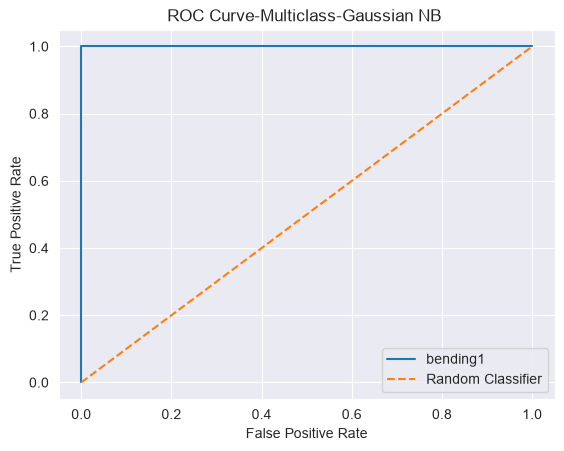

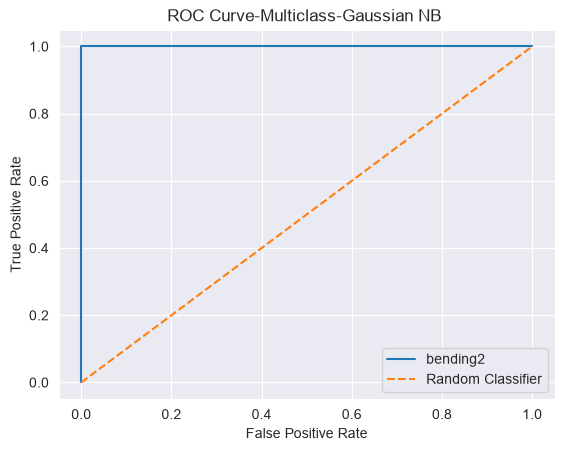

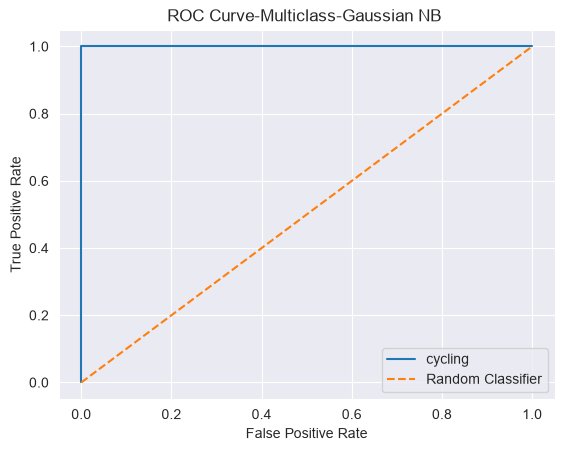

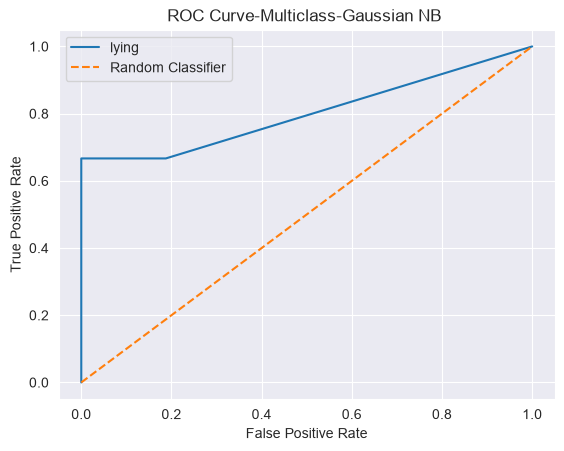

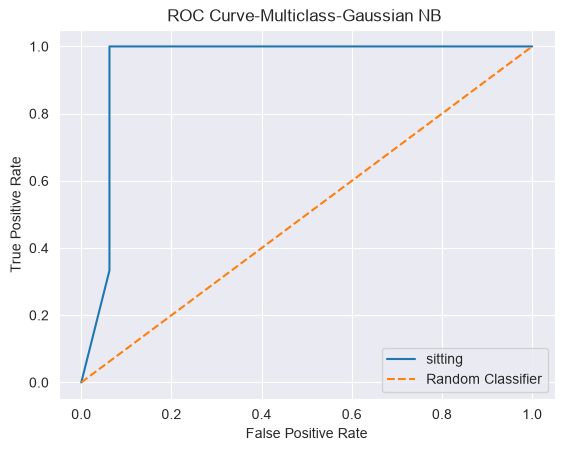

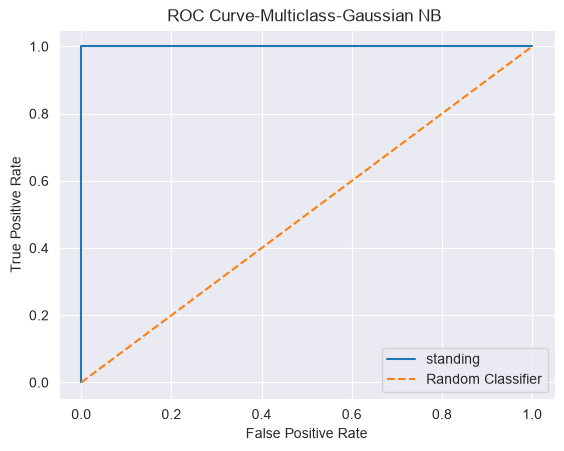

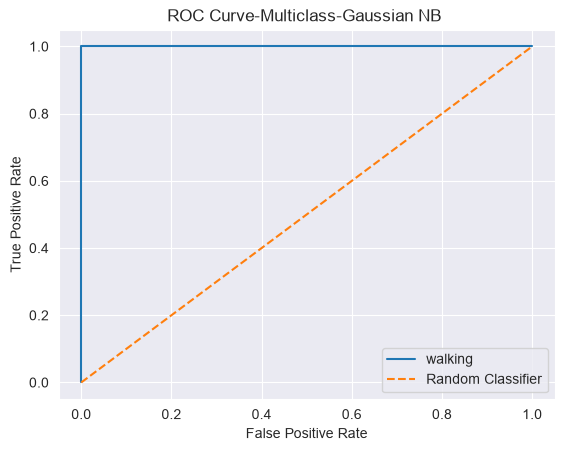

Gaussian Macro-average AUC: 0.9642857142857143


In [80]:
gaussian_prob = final_gaussian.predict_proba(X_gaussian_test)
y_gaussian_bin = label_binarize(y_gaussian_test, classes=final_gaussian.classes_)

for i, activity in enumerate(final_gaussian.classes_):
    fpr, tpr, _ = roc_curve(y_gaussian_bin[:, i], gaussian_prob[:, i])
    single_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=activity)
    plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve-Multiclass-Gaussian NB ")
    plt.legend()
    plt.show()
gaussian_macro_auc = roc_auc_score(y_gaussian_test, gaussian_prob, labels = final_gaussian.classes_, multi_class = "ovr", average = "macro")
print("Gaussian Macro-average AUC:", gaussian_macro_auc)

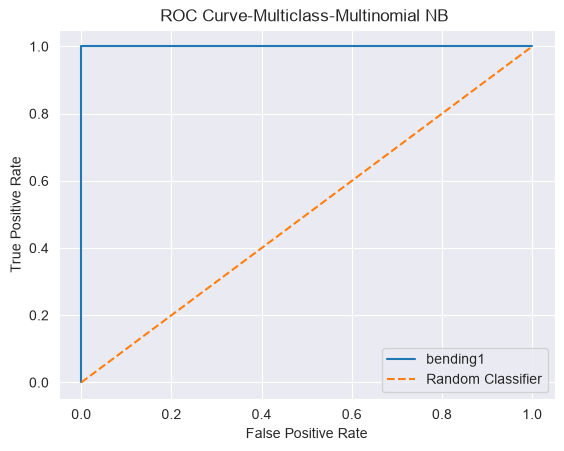

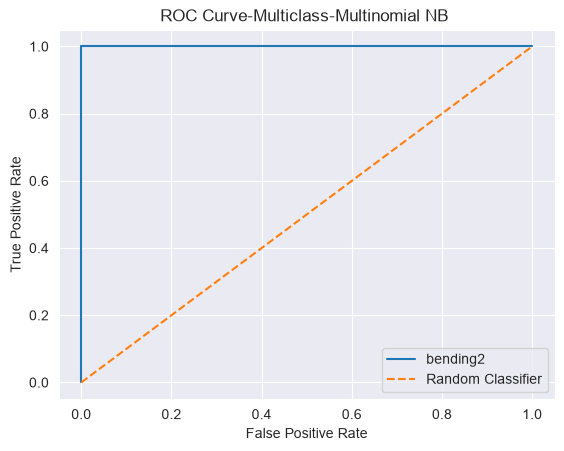

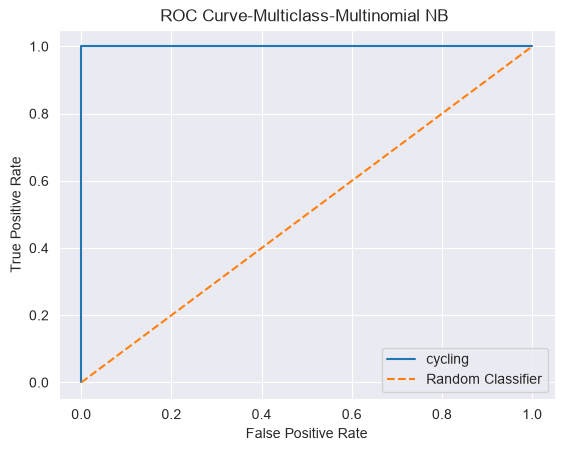

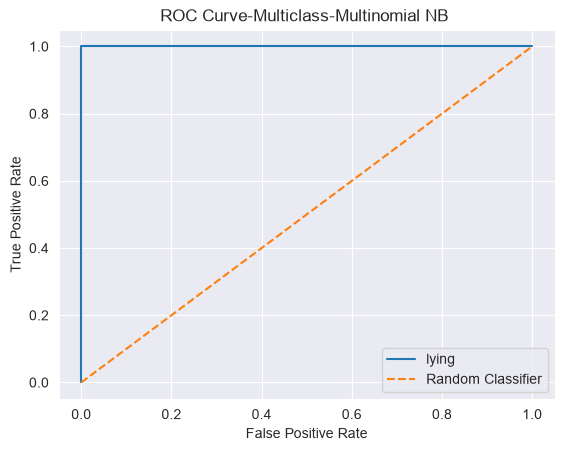

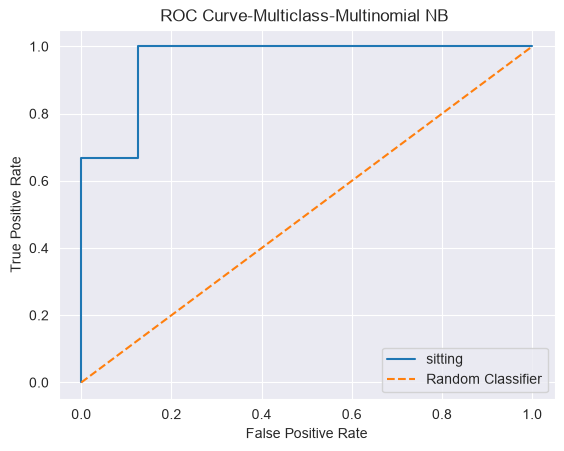

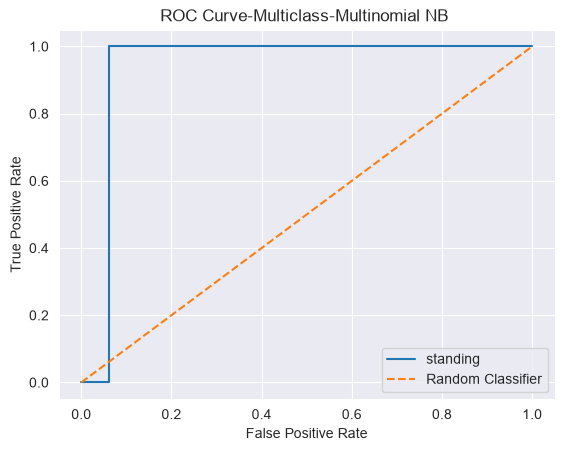

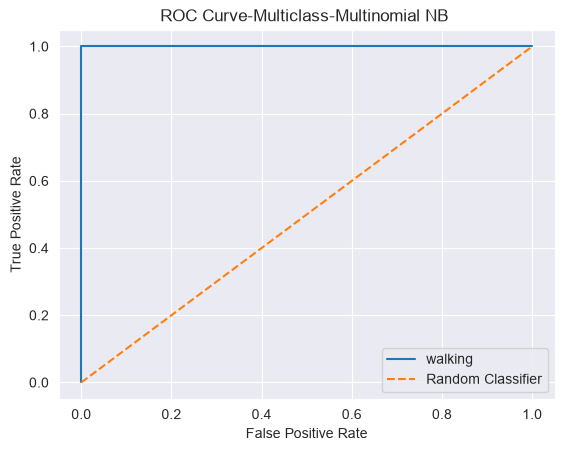

Multinomial Macro AUC: 0.9851190476190476


In [81]:
multinomial_prob = final_multinomial.predict_proba(X_multinomial_test)
y_multinomial_bin = label_binarize(y_multinomial_test, classes=final_multinomial.classes_)
for i, activity in enumerate(final_multinomial.classes_):
    fpr, tpr, _ = roc_curve(y_multinomial_bin[:, i], multinomial_prob[:, i])
    single_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=activity)
    plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve-Multiclass-Multinomial NB ")
    plt.legend()
    plt.show()
multinomial_macro_auc = roc_auc_score(y_multinomial_test, multinomial_prob, labels = final_multinomial.classes_, multi_class = "ovr", average = "macro")
print("Multinomial Macro AUC:", multinomial_macro_auc)

In the best case, both gaussian and multinomial get the same test error at 0.105263, however Multinomial NB macro AUC = 0.9851 and is slightly higher than Gaussian NB Macro AUC = 0.9643. This means multinomial NB has the better overall probability-based distinguishing performance for these seven activities

#### iii. Comparison

Comparing L1-penalized log regression, Gaussian NB and Multinomial Nb, from the results I think multinomial NB is the best for this problem. L1-penalized log regression has the highest CV accuracy but performed less effective on test set than the other two NB. And between the two NB, they have the same test error but Multinomial has higher macro auc scores.

## 3. ISLR 4.8.3

these two questions will be answered in a separate pdf

## 4. ISLR 4.8.7

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9